# Pirate Agent: Demo Notebook

**Programmer:** Michael Soto<br>
**Date:** November 11, 2026<br>
**Version:** 2.0.0<br>
**Course:** CS 499 Computer Science Capstone, Enhancement One (software design and engineering)

**Intent:** show the enhanced package at work: a validated maze, the safety checks on bad input, the reference model
loaded through the checked loader, its route audit, and a new maze trained from scratch.

**Decision:** in CS 370 this notebook *was* the program. Now it only calls the `pirate_agent` package, so every
cell here is something the tests and the command line also exercise, and the notebook can never drift from the code.

## 1. Set up
The package lives in `src/`. Adding it to the path lets the notebook run from a fresh clone without installing anything.

In [1]:
# Make the package importable from a fresh clone, and keep software names out of figure metadata.
import importlib
import sys
from pathlib import Path

%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'metadata': {'Software': None}}
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
print("pirate_agent", importlib.import_module("pirate_agent").__version__)

pirate_agent 2.0.0


## 2. The CS 370 maze, loaded from a file
`mazes/cs370.maze` holds the same 8 x 8 layout the starter notebook hard-coded. Loading it runs every validation check.

In [2]:
from pirate_agent.maze import load_maze, shortest_moves

maze = load_maze(ROOT / "mazes" / "cs370.maze")
print(maze.to_text())
distance = shortest_moves(maze.grid, maze.target)
print(f"{len(maze.free_cells)} free cells; the farthest is {max(distance.values())} moves from the treasure.")

.#......
.#...#..
....#.#.
...#....
..#.....
...#.###
...#....
....#..T

50 free cells; the farthest is 28 moves from the treasure.


## 3. Bad input is refused with a clear reason
Each of these layouts would have crashed the CS 370 code or trained forever. Now each one stops at the door.

In [3]:
from pirate_agent.maze import Maze, MazeError, parse_maze

attempts = {
    "blocked treasure": lambda: Maze.from_grid([[1, 1], [1, 0]]),
    "cut-off cell": lambda: Maze.from_grid([[1, 0, 1], [0, 1, 1], [1, 1, 1]]),
    "stray character": lambda: parse_maze("..\n.x\n", source="typo.maze"),
}
for name, attempt in attempts.items():
    try:
        attempt()
    except MazeError as error:
        print(f"{name:<17} -> {error}")

blocked treasure  -> the treasure cell (1, 1) is a wall; the treasure must sit on a free cell
cut-off cell      -> 1 free cell(s) cannot reach the treasure, for example (0, 0); every free cell must have a path to the treasure
stray character   -> typo.maze line 2, column 2: unexpected character 'x'; use '#' for walls, '.' for free cells and 'T' for the treasure


## 4. The reference model, loaded through the checked loader
`pretrained/cs370-seed1671` was trained by `pirate-agent train --config configs/default.toml`. Before Keras reads the model, its SHA-256 must match the run log, the archive must hold only the files Keras writes, and every layer class must be on the allowlist.

In [4]:
from pirate_agent.agent import DQNAgent
from pirate_agent.audit import audit_policy, route_grid
from pirate_agent.config import TrainingConfig
from pirate_agent.runlog import maze_from_log, read_run_log

run = ROOT / "pretrained" / "cs370-seed1671"
record = read_run_log(run / "run.json")
agent = DQNAgent.from_file(run / "model.keras", record["model"]["sha256"], TrainingConfig(), maze.size)
result = record["result"]
games, moves = result["epochs"], result["moves"]
print(f"Trained for {games} games ({moves:,} moves) in {result['seconds']} s: {result['stop_reason']}")

report = audit_policy(maze_from_log(record), agent.greedy_action)
print(report.summary())
print()
print(route_grid(report, maze))

Trained for 286 games (19,843 moves) in 20.6 s: solved


50 of 50 free cells reach the treasure, 47 of them by a shortest route.
Longest route: 28 moves from (7, 3); the fewest possible is 28.

26*   # 18  17  16  15  14  13 
25*   # 19  18  17    # 13  12 
24* 21  20  19    #  9    # 11 
23  22  21    #  7   8   9  10 
24  23    #  7   6   7   8   9 
25  24  25    #  5    #   #   #
26  25  26    #  4   3   2   1 
27  26  27  28    #  2   1    T


Each number is the route length from that cell; `*` marks a cell where a shorter route exists. The pirate wins from every cell.

In [5]:
from pirate_agent.audit import play_greedy, route_map
from pirate_agent.maze import MazeEnv

route, won = play_greedy(MazeEnv(maze), agent.greedy_action, (0, 0))
print(route_map(maze, route))
outcome = "won" if won else "lost"
print(f"From (0, 0): {outcome} in {len(route) - 1} moves; the fewest possible is {distance[(0, 0)]}.")

S # o o o o o o
o # o . . # . o
o o o . # . # o
o o . # o o o o
. . # . o . . .
. . . # o # # #
. . . # o o o .
. . . . # . o T
From (0, 0): won in 26 moves; the fewest possible is 24.


## 5. How the win rate rose
The run's `history.csv` has one row per training game.

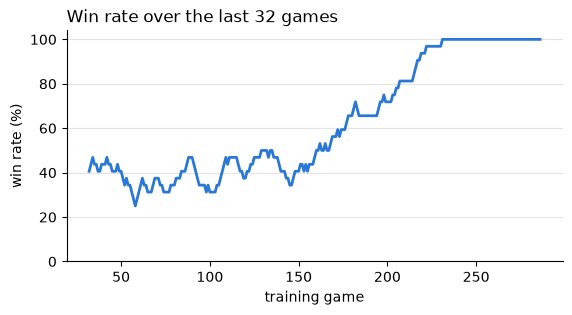

In [6]:
import csv

import matplotlib.pyplot as plt

with (run / "history.csv").open(encoding="utf-8") as stream:
    rows = list(csv.DictReader(stream))
window = record["training"]["win_window"]
games = [int(r["epoch"]) + 1 for r in rows][window - 1 :]
rates = [100 * float(r["win_rate"]) for r in rows][window - 1 :]

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.plot(games, rates, color="#2a78d6", linewidth=2)
ax.set_ylim(0, 104)
ax.set_ylabel("win rate (%)")
ax.set_xlabel("training game")
ax.set_title(f"Win rate over the last {window} games", loc="left")
ax.grid(axis="y", color="#e4e3df")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## 6. A new maze, trained from scratch
The agent is no longer tied to one maze. This generates a 5 x 5 maze in which every free cell can reach the treasure, trains a fresh agent on it, and audits the result.

In [7]:
import logging

from pirate_agent.agent import configure_determinism
from pirate_agent.maze import generate_maze
from pirate_agent.trainer import Trainer

logging.getLogger("pirate_agent").setLevel(logging.WARNING)
small = generate_maze(5, 5, wall_density=0.25, seed=4)
print(small.to_text())

config = TrainingConfig(seed=21, max_epochs=1000, patience=300)
configure_determinism(config.seed)
fresh = DQNAgent.create(small.size, config)
outcome = Trainer(fresh, small, config).train()
print(f"{outcome.stop_reason} after {outcome.epochs} games in {outcome.seconds:.1f} s")
print(audit_policy(small, fresh.greedy_action).summary())

...#.
..#..
.....
...#.
...#T



solved after 85 games in 2.5 s
20 of 20 free cells reach the treasure, 16 of them by a shortest route.
Longest route: 10 moves from (0, 2); the fewest possible is 8.


## 7. The same steps from the command line
```
python -m pirate_agent train --config configs/default.toml
python -m pirate_agent evaluate --run pretrained/cs370-seed1671
python -m pirate_agent play --run pretrained/cs370-seed1671 --start 0,0
python -m pirate_agent generate --rows 5 --cols 5 --seed 4 --out mazes/small.maze
```